# 01 · Exploratory data analysis: the fleet, its readouts and what changes before a repair

**Question for this notebook:** what does the Scania Component X data look like, and what
does that mean for the reliability analysis (notebook 02) and the risk model (notebook 03)?

Data: SCANIA Component X dataset, Swedish National Data Service,
https://doi.org/10.5878/bnh5-ka77, CC BY 4.0.

Reading guide:
- **Unit of analysis = vehicle.** Every count below says whether it is per vehicle or per readout.
- **`time_step` is anonymized operating time**, not calendar time, and readouts are irregular.
  Durations are reported in *time steps*.
- Variables are anonymized: "counter 171" or "histogram 397, bin 12", with no physical meaning implied.
- This notebook reads only `data/pdm.duckdb` (built by `python src/build_dataset.py`). Heavy
  aggregation happens in DuckDB; only small summaries come into pandas.
- **Test labels are not looked at here.** Test is only used for its sizes, its readout
  pattern and its spec mix (inputs, not outcomes); its labels are touched once, in notebook 04.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import viz
from make_features_sql import COUNTERS, HISTOGRAMS, FEATURE_GROUPS, FEATURES

viz.apply_style()
FIGS = ROOT / "docs" / "figures"
SPLITS = ["train", "validation", "test"]
con = duckdb.connect(str(ROOT / "data" / "pdm.duckdb"), read_only=True)


def q(sql, *params):
    return con.execute(sql, list(params)).df()


pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 30)

## 1. Fleet and split sizes

How many vehicles and readouts are in each split, and are the splits really disjoint by vehicle?

In [2]:
sizes = q('''
    SELECT split,
           count(DISTINCT vehicle_id)                         AS vehicles,
           count(*)                                           AS readouts,
           count(*) / count(DISTINCT vehicle_id)              AS readouts_per_vehicle,
           min(time_step)                                     AS min_time_step,
           max(time_step)                                     AS max_time_step
    FROM readouts GROUP BY split
''').set_index("split").loc[SPLITS]
sizes["share_of_vehicles"] = sizes["vehicles"] / sizes["vehicles"].sum()
shared = q('''SELECT count(*) AS n FROM (SELECT vehicle_id FROM readouts
              GROUP BY vehicle_id HAVING count(DISTINCT split) > 1)''')["n"].iloc[0]
print(f"vehicle_ids appearing in more than one split: {shared}")
sizes

vehicle_ids appearing in more than one split: 0


,vehicles,readouts,readouts_per_vehicle,min_time_step,max_time_step,share_of_vehicles
split,,,,,,
train,23550,1122452,47.663,0.000,507.400,0.700
validation,5046,196227,38.888,0.000,456.600,0.150
test,5045,198140,39.275,0.000,447.600,0.150


**Interpretation.** The fleet splits 70 / 15 / 15% by vehicle (23,550 / 5,046 / 5,045), and no vehicle appears in two splits, so vehicle-level evaluation is clean. Training vehicles have more readouts on average (47.7 vs about 39) because they are observed for the whole study, while validation and test vehicles are cut at a random readout. `time_step` starts at 0 in every split.

## 2. Readouts per vehicle and sampling gaps

Readouts arrive irregularly. Two things matter for modelling: how much history a vehicle has
at a prediction point, and how far apart its readouts are (which is why `sql/03_features.sql`
divides changes by the time gap instead of using raw differences).

Validation and test vehicles are cut at a random last readout, so they should have *fewer*
readouts and shorter spans than training vehicles, which are observed for the whole study.

In [3]:
per_vehicle = q('''
    SELECT split, vehicle_id, count(*) AS n_readouts,
           min(time_step) AS first_ts, max(time_step) AS last_ts,
           max(time_step) - min(time_step) AS span
    FROM readouts GROUP BY ALL
''')
gap_q = q('''
    SELECT split,
           quantile_cont(dt_prev, [0.1, 0.25, 0.5, 0.75, 0.9, 0.99]) AS q,
           avg((dt_prev > 20)::INT) AS share_gt_20
    FROM readout_features WHERE dt_prev IS NOT NULL GROUP BY split
''').set_index("split").loc[SPLITS]
# Within-vehicle irregularity: coefficient of variation of a vehicle's own gaps.
irregular = q('''
    SELECT split, median(cv) AS median_gap_cv FROM (
        SELECT split, vehicle_id, stddev_samp(dt_prev) / avg(dt_prev) AS cv
        FROM readout_features WHERE dt_prev IS NOT NULL GROUP BY ALL HAVING count(*) >= 3)
    GROUP BY split
''').set_index("split").loc[SPLITS]

summary = per_vehicle.groupby("split")[["n_readouts", "first_ts", "span"]].describe(
    percentiles=[0.1, 0.5, 0.9]).loc[SPLITS]
summary = summary.loc[:, (slice(None), ["10%", "50%", "90%", "max"])]
gaps = pd.DataFrame(gap_q["q"].tolist(), index=gap_q.index,
                    columns=["gap_p10", "gap_p25", "gap_median", "gap_p75", "gap_p90", "gap_p99"])
gaps["share_gaps_over_20"] = gap_q["share_gt_20"]
gaps["median_within_vehicle_gap_cv"] = irregular["median_gap_cv"]
display(summary)
gaps

n_readouts                       first_ts                       \
                  10%    50%    90%     max      10%   50%    90%     max   
split                                                                       
train          15.000 43.000 83.000 303.000    0.200 5.200 15.400 316.400   
validation     11.000 34.000 72.500 209.000    0.200 5.200 15.400 187.800   
test           11.000 34.000 74.000 262.000    0.400 5.200 15.000 169.800   

              span                          
               10%     50%     90%     max  
split                                       
train      125.400 208.400 354.420 504.200  
validation  79.200 163.400 310.900 449.600  
test        80.200 165.000 312.000 442.200

,gap_p10,gap_p25,gap_median,gap_p75,gap_p90,gap_p99,share_gaps_over_20,median_within_vehicle_gap_cv
split,,,,,,,,
train,0.600,1.600,4.400,6.200,7.600,26.400,0.018,0.691
validation,0.600,1.600,4.600,6.200,7.400,25.400,0.017,0.667
test,0.600,1.600,4.400,6.200,7.400,25.800,0.017,0.668


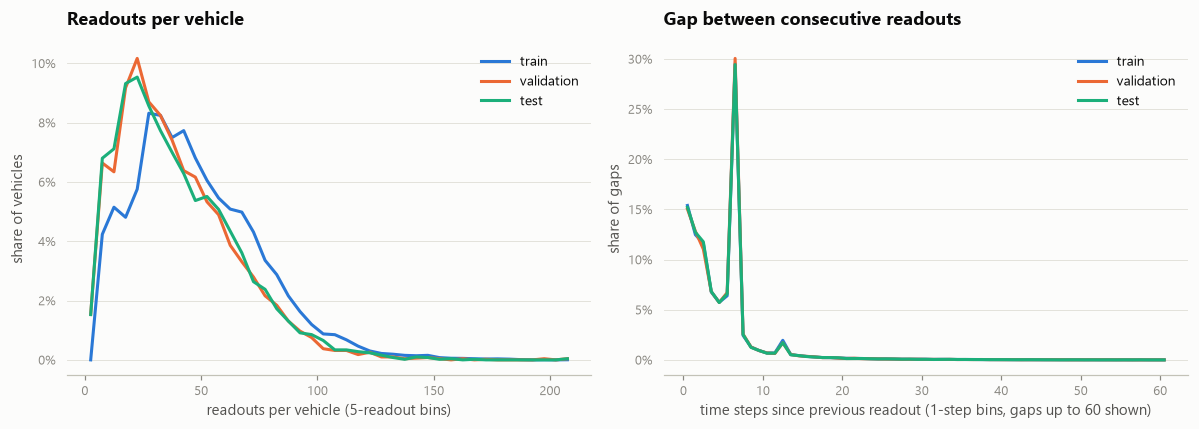

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: readouts per vehicle, share of vehicles per 5-readout bin.
ax = axes[0]
bins = np.arange(0, 211, 5)
for split in SPLITS:
    n = per_vehicle.loc[per_vehicle.split == split, "n_readouts"]
    share, edges = np.histogram(n, bins=bins)
    share = share / share.sum()
    ax.plot(edges[:-1] + 2.5, share, color=viz.SPLIT_COLORS[split], label=split)
ax.set_title("Readouts per vehicle")
ax.set_xlabel("readouts per vehicle (5-readout bins)")
ax.set_ylabel("share of vehicles")
ax.yaxis.set_major_formatter(viz.PCT)
ax.legend(loc="upper right")

# Right: gap between consecutive readouts, share of gaps per 1-step bin (log x to show the tail).
gap_hist = q('''
    SELECT split, floor(dt_prev) AS gap_bin, count(*) AS n
    FROM readout_features WHERE dt_prev IS NOT NULL GROUP BY ALL
''')
ax = axes[1]
for split in SPLITS:
    g = gap_hist[gap_hist.split == split].sort_values("gap_bin")
    g = g[g.gap_bin <= 60]
    ax.plot(g.gap_bin + 0.5, g.n / gap_hist.loc[gap_hist.split == split, "n"].sum(),
            color=viz.SPLIT_COLORS[split], label=split)
ax.set_title("Gap between consecutive readouts")
ax.set_xlabel("time steps since previous readout (1-step bins, gaps up to 60 shown)")
ax.set_ylabel("share of gaps")
ax.yaxis.set_major_formatter(viz.PCT)
ax.legend(loc="upper right")
fig.tight_layout()
viz.save(fig, "01_readouts_and_gaps", FIGS)
plt.show()

**Interpretation.** Vehicles enter the data close to when Component X was fitted (median first readout at 5.2 time steps in every split). Validation and test vehicles have shorter histories (median 34 readouts vs 43 in training), as expected from the truncation. Sampling is irregular but follows a pattern: about 30% of gaps are 6–7 steps (a regular reporting cadence), about 28% are under 2 steps, the median gap is 4.4–4.6 steps, and 1.7–1.8% are over 20 steps. A typical vehicle's own gaps vary by about 0.7 of their mean (coefficient of variation). The gap distribution is the same in all three splits. **Implication:** features must be rates per time step rather than raw differences between readouts (as in `sql/03_features.sql`), and history length (`readouts_so_far`) varies enough that it belongs in the model.

## 3. Repaired vs censored training vehicles

In training, each vehicle either has a Component X repair at `length_of_study_time_step`
(`in_study_repair = 1`) or is right-censored there (no repair seen). Comparing the two groups
shows how much information censoring removes, and whether the two groups are observed
differently (which a naive model could pick up as a shortcut).

In [5]:
tte = q('''
    SELECT t.vehicle_id, t.length_of_study_time_step AS study_length, t.in_study_repair,
           v.n_readouts, v.first_ts, v.last_ts,
           t.length_of_study_time_step - v.last_ts AS end_minus_last_readout
    FROM train_tte t
    JOIN (SELECT vehicle_id, count(*) AS n_readouts, min(time_step) AS first_ts, max(time_step) AS last_ts
          FROM readouts WHERE split = 'train' GROUP BY 1) v USING (vehicle_id)
''')
tte["status"] = np.where(tte.in_study_repair == 1, "repaired", "censored")
status = tte.groupby("status").agg(
    vehicles=("vehicle_id", "size"),
    study_length_p10=("study_length", lambda s: s.quantile(0.1)),
    study_length_median=("study_length", "median"),
    study_length_p90=("study_length", lambda s: s.quantile(0.9)),
    readouts_median=("n_readouts", "median"),
    end_minus_last_readout_median=("end_minus_last_readout", "median"),
)
status["share"] = status["vehicles"] / status["vehicles"].sum()
status

,vehicles,study_length_p10,study_length_median,study_length_p90,readouts_median,end_minus_last_readout_median,share
status,,,,,,,
censored,21278,141.000,219.000,368.400,43.000,2.200,0.904
repaired,2272,112.200,208.400,325.780,43.000,1.800,0.096


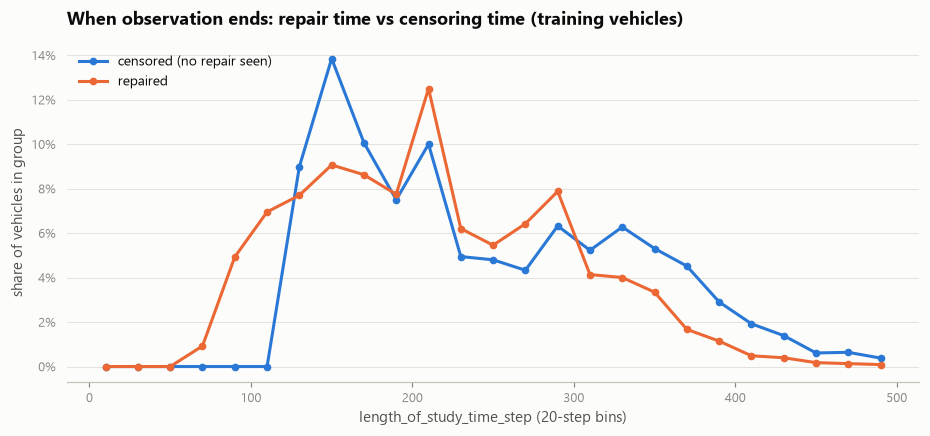

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 520, 20)
for grp, color, label in [("censored", viz.BLUE, "censored (no repair seen)"),
                          ("repaired", viz.ORANGE, "repaired")]:
    s = tte.loc[tte.status == grp, "study_length"]
    share, edges = np.histogram(s, bins=bins)
    ax.plot(edges[:-1] + 10, share / share.sum(), color=color, marker="o", label=label)
ax.set_title("When observation ends: repair time vs censoring time (training vehicles)")
ax.set_xlabel("length_of_study_time_step (20-step bins)")
ax.set_ylabel("share of vehicles in group")
ax.yaxis.set_major_formatter(viz.PCT)
ax.legend(loc="upper left")
viz.save(fig, "01_study_length", FIGS)
plt.show()

**Interpretation.** Only 9.6% of training vehicles (2,272) have a repair; 90.4% are censored. The two groups end at similar points overall (median 208 vs 219 time steps), but the shapes differ. **No vehicle is censored before 121 time steps**, while repairs start at 73.4, so the 291 repairs before 120 steps (12.8% of all repairs) happen while every vehicle is still under observation. After that, censoring is spread over the rest of the range. A crude "9.6% get repaired" therefore understates the lifetime risk, because most trucks leave the study before they could fail. That is what Kaplan–Meier fixes in notebook 02. Repaired and censored vehicles have the same median number of readouts (43) and a similar gap between their last readout and the end of observation (1.8 vs 2.2 steps), so the observation pattern itself does not reveal the outcome.

### 3b. Label mix: what a prediction point looks like in each split

Validation (and test) carry one label per vehicle, for its last readout. Training has a label
for every readout (from `sql/02_labels.sql`). `src/build_dataset.py` already compared the
validation mix with one random readout per training vehicle (20 seeds) and saved it to
`data/processed/label_check.csv`. Repeated here because it drives the sampling choice in notebook 03.

In [7]:
label_check = pd.read_csv(ROOT / "data" / "processed" / "label_check.csv")
lc = label_check[["class_label", "train_random_mean_share", "validation_share",
                  "share_ratio_train_to_val"]].set_index("class_label")
print(f"Random training readouts with an unknown (NULL) class: {label_check.null_share_of_draws.iloc[0]:.1%}")
lc

Random training readouts with an unknown (NULL) class: 21.1%


,train_random_mean_share,validation_share,share_ratio_train_to_val
class_label,,,
0,0.965,0.973,0.991
1,0.017,0.003,5.297
2,0.009,0.003,3.144
3,0.004,0.006,0.754
4,0.005,0.015,0.350


**Interpretation.** One random readout per training vehicle gives about the right share of class 0 (96.5% vs 97.3%). But among the urgent classes it has 5.3× too much class 1 and only 0.35× the class 4 share. Validation's cut points sit closer to a repair than uniform sampling would put them. On top of that, 21% of random training readouts have an unknown class (censored, within 48 steps of the end of observation). Notebook 03 therefore has to choose and justify how it samples or weights training prediction points, judged on validation.

## 4. Vehicle specifications by split

Spec_0 … Spec_7 are anonymized categories (Cat0 … Cat28). Two questions:
1. Are the splits drawn from the same fleet mix? If a category is common in test but rare in
   training, the model will be extrapolating there.
2. Do crude repair shares differ by category in training? These are *shares of vehicles
   repaired during the study*, not rates: vehicles are observed for different lengths, so a
   proper comparison needs survival curves (notebook 02). Here it is only a pointer.

The split difference is summarised by the **total variation distance** (TVD) between a
split's category shares and training's: half the sum of absolute share differences, 0 =
identical mix, 1 = no overlap.

In [8]:
spec_cols = [f"Spec_{i}" for i in range(8)]
specs = q("SELECT * FROM specifications")
train_specs = specs[specs.split == "train"].merge(tte[["vehicle_id", "in_study_repair"]], on="vehicle_id")

rows = []
for col in spec_cols:
    shares = pd.crosstab(specs[col], specs["split"], normalize="columns")[SPLITS]
    rows.append({
        "spec": col,
        "categories": specs[col].nunique(),
        "top_category": shares["train"].idxmax(),
        "top_category_share_train": shares["train"].max(),
        "tvd_validation_vs_train": 0.5 * (shares["validation"] - shares["train"]).abs().sum(),
        "tvd_test_vs_train": 0.5 * (shares["test"] - shares["train"]).abs().sum(),
    })
spec_summary = pd.DataFrame(rows).set_index("spec")
spec_summary

,categories,top_category,top_category_share_train,tvd_validation_vs_train,tvd_test_vs_train
spec,,,,,
Spec_0,3,Cat0,0.816,0.004,0.002
Spec_1,30,Cat1,0.567,0.016,0.023
Spec_2,21,Cat1,0.609,0.013,0.013
Spec_3,4,Cat0,0.613,0.015,0.009
Spec_4,2,Cat0,0.971,0.004,0.004
Spec_5,5,Cat0,0.809,0.004,0.010
Spec_6,19,Cat0,0.432,0.020,0.006
Spec_7,9,Cat0,0.328,0.019,0.012


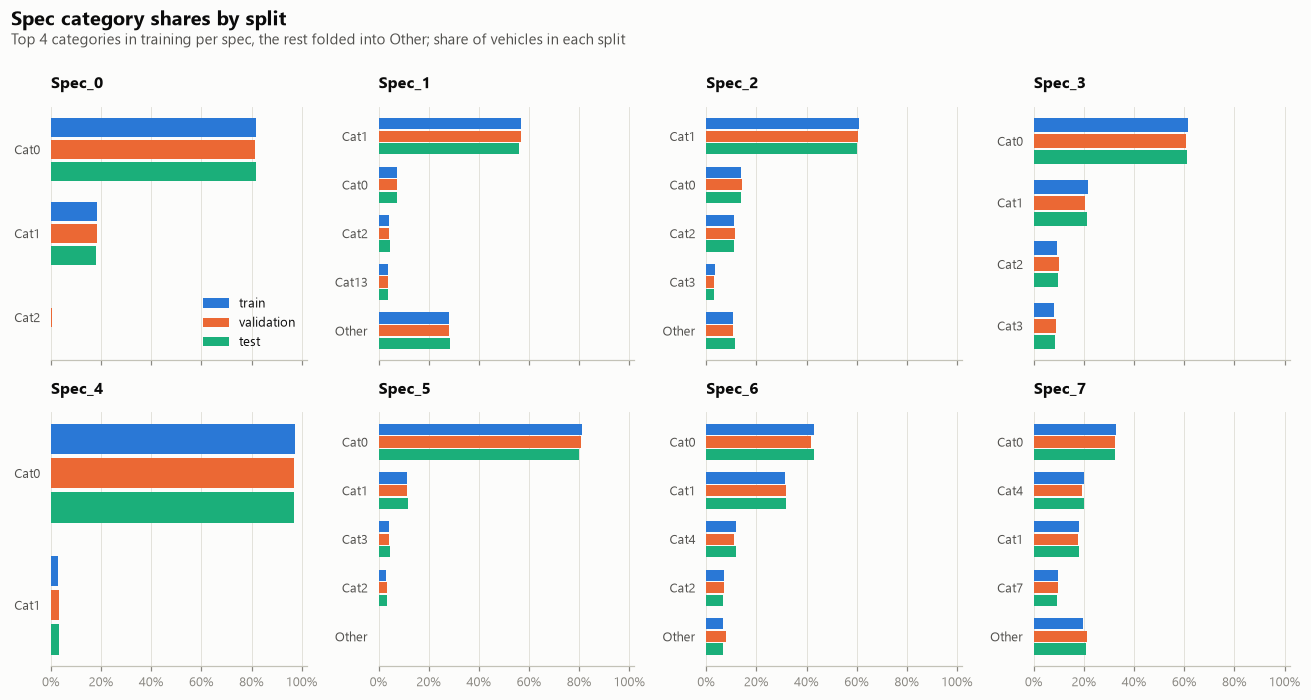

In [9]:
TOP = 4
fig, axes = plt.subplots(2, 4, figsize=(12, 6.2), sharex=True)
for ax, col in zip(axes.flat, spec_cols):
    shares = pd.crosstab(specs[col], specs["split"], normalize="columns")[SPLITS]
    top = shares["train"].nlargest(TOP).index
    shown = shares.loc[top]
    if len(shares) > TOP:
        shown.loc["Other"] = shares.drop(index=top).sum()
    y = np.arange(len(shown))
    h = 0.26
    for i, split in enumerate(SPLITS):
        ax.barh(y + (i - 1) * h, shown[split], height=h - 0.03, color=viz.SPLIT_COLORS[split],
                label=split)
    ax.set_yticks(y, shown.index)
    ax.invert_yaxis()
    ax.set_title(col, fontsize=10.5)
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(viz.PCT)
    ax.tick_params(axis="y", labelsize=8.5, colors=viz.INK2)
axes[0, 0].legend(loc="lower right", fontsize=8.5)
viz.suptitle(fig, "Spec category shares by split",
             f"Top {TOP} categories in training per spec, the rest folded into Other; share of vehicles in each split")
fig.tight_layout()
viz.save(fig, "01_specs_by_split", FIGS)
plt.show()

**Interpretation.** The splits come from the same fleet mix: the total variation distance from training is at most 0.023 for every spec, in both validation and test. Several specs are dominated by one category (Spec_4: 97% Cat0; Spec_0: 82% Cat0), while Spec_1, Spec_2 and Spec_6 have 19–30 categories with long tails. Rare categories will need to be grouped (or left to the tree model) rather than one-hot encoded one by one.

In [10]:
# Crude repair share by category, training only, categories with >= 200 vehicles.
crude = []
for col in spec_cols:
    g = train_specs.groupby(col)["in_study_repair"].agg(["size", "mean"])
    g = g[g["size"] >= 200]
    crude.append({"spec": col, "categories_with_200plus": len(g),
                  "lowest_repair_share": g["mean"].min(), "lowest_category": g["mean"].idxmin(),
                  "highest_repair_share": g["mean"].max(), "highest_category": g["mean"].idxmax()})
crude = pd.DataFrame(crude).set_index("spec")
crude["ratio_high_to_low"] = crude["highest_repair_share"] / crude["lowest_repair_share"]
print(f"Overall crude repair share in training: {train_specs.in_study_repair.mean():.1%}")
crude

Overall crude repair share in training: 9.6%


,categories_with_200plus,lowest_repair_share,lowest_category,highest_repair_share,highest_category,ratio_high_to_low
spec,,,,,,
Spec_0,2,0.068,Cat1,0.103,Cat0,1.506
Spec_1,16,0.027,Cat16,0.154,Cat17,5.659
Spec_2,8,0.015,Cat12,0.198,Cat5,13.607
Spec_3,4,0.041,Cat3,0.120,Cat1,2.906
Spec_4,2,0.096,Cat0,0.123,Cat1,1.285
Spec_5,4,0.083,Cat3,0.119,Cat1,1.442
Spec_6,6,0.066,Cat4,0.120,Cat2,1.824
Spec_7,9,0.015,Cat8,0.141,Cat1,9.310


**Interpretation.** Crude repair shares differ a lot between categories of some specs. Spec_2 ranges from 1.5% (Cat12) to 19.8% (Cat5), a 13.6× ratio; Spec_7 ranges from 1.5% to 14.1%, and Spec_1 from 2.7% to 15.4%. Spec_0, Spec_4 and Spec_5 differ by at most 1.5×. These are shares, not rates, and categories may differ in how long they were observed, so notebook 02 tests this properly (Kaplan–Meier by spec, log-rank tests with a multiple-testing correction).

## 5. What changes in the 48 steps before a repair?

**Design (explained before the code).** Comparing readouts close to a repair with *all*
other readouts would mostly compare old trucks with young ones, because repairs happen
later in life. So each repaired vehicle (a *case*) gets a **matched healthy truck** (a *control*):

- **Case:** a repaired training vehicle with repair at operating time *T*. Its window is its
  readouts with time to repair in [0, 48]; `steps_before` = time to repair.
- **Control:** a censored training vehicle that
  1. has the **same Spec_0** (the spec with the fewest, largest categories),
  2. was **observed until at least T + 48** with no repair, so at time *T* it is certainly
     class 0 (no repair within 48 steps), and
  3. had a first readout at or before *T*, so it has data in the window.

  One control per case is drawn at random (hash-ordered, so reproducible). Controls are
  drawn with replacement, so one censored truck can serve several cases.
- The control's window is its readouts with time_step in [T − 48, T]; `steps_before` = T − time_step.
  Case and control are therefore compared **at the same operating age**.

Both groups use the per-readout features from `sql/03_features.sql`, which only look backwards.

In [11]:
pairs = q('''
    WITH spec AS (SELECT vehicle_id, Spec_0 FROM specifications WHERE split = 'train'),
    first_seen AS (SELECT vehicle_id, min(time_step) AS first_ts FROM readouts
                   WHERE split = 'train' GROUP BY 1),
    cases AS (
        SELECT t.vehicle_id AS case_id, t.length_of_study_time_step AS T, s.Spec_0
        FROM train_tte t JOIN spec s USING (vehicle_id) WHERE t.in_study_repair = 1),
    pool AS (
        SELECT t.vehicle_id AS control_id, t.length_of_study_time_step AS L, s.Spec_0, f.first_ts
        FROM train_tte t JOIN spec s USING (vehicle_id) JOIN first_seen f USING (vehicle_id)
        WHERE t.in_study_repair = 0)
    SELECT case_id, T, control_id FROM (
        SELECT c.case_id, c.T, p.control_id,
               row_number() OVER (PARTITION BY c.case_id ORDER BY hash(c.case_id, p.control_id, 2024)) AS rn
        FROM cases c JOIN pool p
          ON p.Spec_0 = c.Spec_0 AND p.L >= c.T + 48 AND p.first_ts <= c.T)
    WHERE rn = 1
''')
n_cases = int(tte.in_study_repair.sum())
print(f"cases matched: {len(pairs):,} of {n_cases:,} repaired vehicles; "
      f"distinct controls: {pairs.control_id.nunique():,}")
con.register("pairs_df", pairs)

feature_list = ", ".join(f'f."{c}"' for c in FEATURES if c != "time_step")
window = q(f'''
    SELECT 'repaired' AS grp, p.case_id AS pair_id, f.vehicle_id, f.time_step,
           p.T - f.time_step AS steps_before, {feature_list}
    FROM pairs_df p JOIN readout_features f ON f.split = 'train' AND f.vehicle_id = p.case_id
    WHERE p.T - f.time_step BETWEEN 0 AND 48
    UNION ALL
    SELECT 'healthy', p.case_id, f.vehicle_id, f.time_step,
           p.T - f.time_step, {feature_list}
    FROM pairs_df p JOIN readout_features f ON f.split = 'train' AND f.vehicle_id = p.control_id
    WHERE p.T - f.time_step BETWEEN 0 AND 48
''')
window["bin"] = np.minimum(window.steps_before // 6, 7).astype(int)   # 8 bins of 6 steps
window["bin_mid"] = window["bin"] * 6 + 3
window.groupby("grp").agg(readouts=("vehicle_id", "size"), vehicles=("vehicle_id", "nunique"),
                          pairs=("pair_id", "nunique"))

cases matched: 2,267 of 2,272 repaired vehicles; distinct controls: 2,012


,readouts,vehicles,pairs
grp,,,
healthy,22797,2000,2249
repaired,25696,2257,2257


Trajectories are shown as the **median per 6-step bin** of `steps_before`, with time running
left to right towards the repair (or the matched time *T* for healthy trucks). Medians, because
the anonymized counters are heavily skewed. Each panel has its own y-scale: the units are
anonymized, so only the *gap between the two lines* and its *trend* are meaningful.

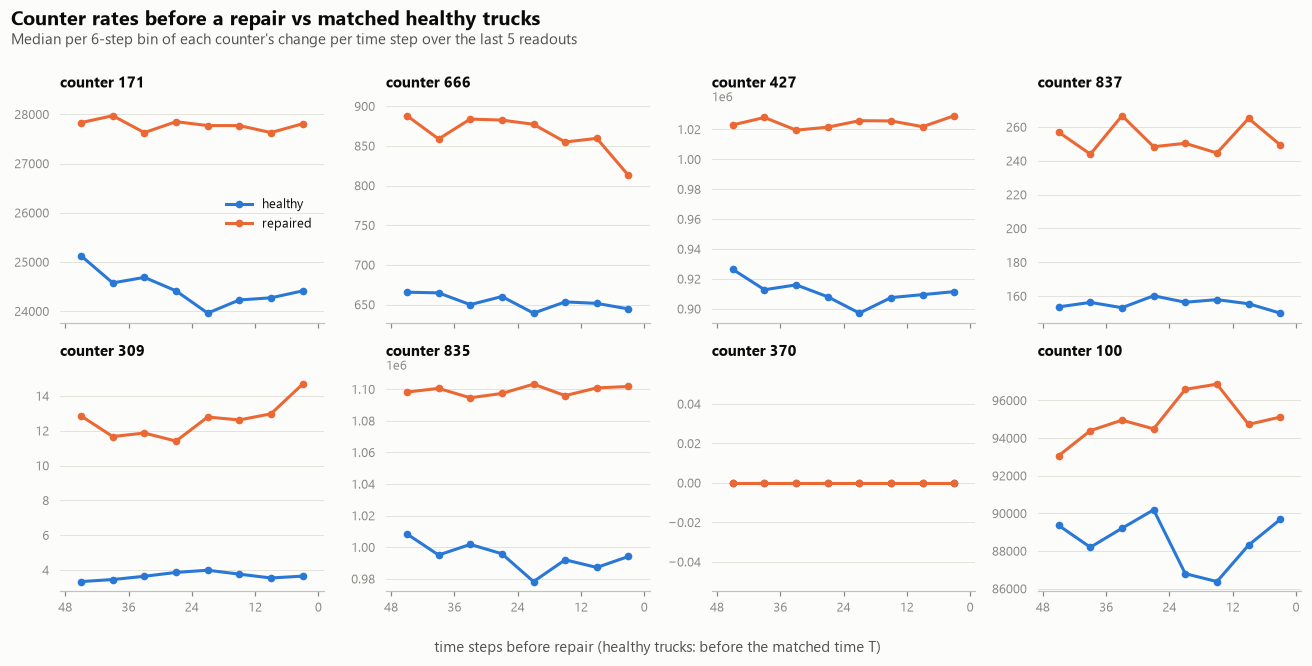

In [12]:
def trajectory_grid(features, titles, name, title, subtitle, ncols=4):
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.9 * nrows), sharex=True)
    med = window.groupby(["grp", "bin_mid"])[features].median()
    for ax, f, t in zip(axes.flat, features, titles):
        for grp in ["healthy", "repaired"]:
            s = med.loc[grp, f]
            ax.plot(s.index, s.values, color=viz.GROUP_COLORS[grp], marker="o", label=grp)
        ax.set_title(t, fontsize=10)
        ax.set_xlim(49, -1)                      # time flows towards the repair
        ax.set_xticks([48, 36, 24, 12, 0])
    for ax in axes.flat[len(features):]:
        ax.set_visible(False)
    fig.supxlabel("time steps before repair (healthy trucks: before the matched time T)",
                  fontsize=9.5, color=viz.INK2)
    axes.flat[0].legend(loc="best", fontsize=8.5)
    viz.suptitle(fig, title, subtitle)
    fig.tight_layout()
    viz.save(fig, name, FIGS)
    plt.show()
    return med


med_c = trajectory_grid(
    [f"c{c}_rate_5" for c in COUNTERS], [f"counter {c}" for c in COUNTERS],
    "01_counters_before_repair", "Counter rates before a repair vs matched healthy trucks",
    "Median per 6-step bin of each counter's change per time step over the last 5 readouts")

**Interpretation.** At the same operating age, trucks heading for a repair run most counters **faster** than matched healthy trucks. Examples: counter 309 at about 12–15 vs about 4 per time step, counter 837 at about 250 vs about 155, counter 427 about 12% higher. The gap is **already there 48 steps before the repair and stays roughly flat**. The only visible trends are counter 666 falling in the last 12 steps and counter 309 rising in the last 6. Counter 370's median rate is 0 in both groups (it is unchanged between 71% of consecutive readouts), so its median carries no information here. Read together, the counters mostly mark *heavier-used trucks* rather than a degradation that starts shortly before the repair.

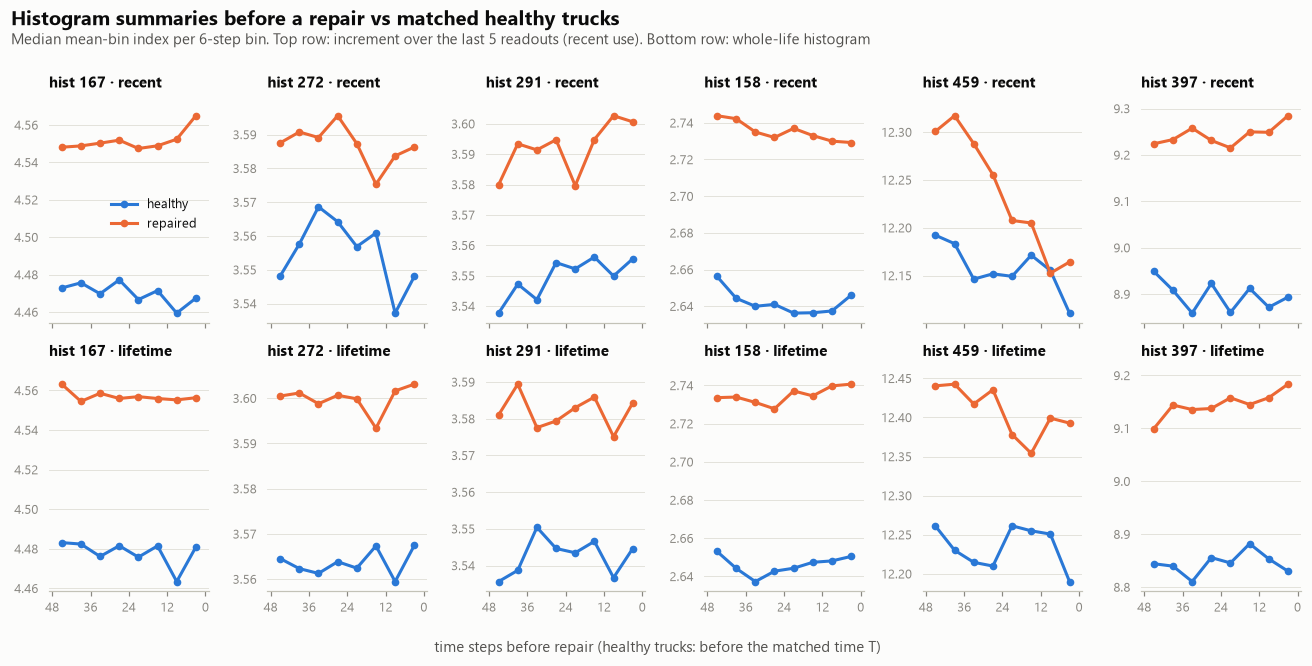

In [13]:
hist_feats = [f"h{h}_recent5_mean_bin" for h in HISTOGRAMS] + [f"h{h}_mean_bin" for h in HISTOGRAMS]
hist_titles = ([f"hist {h} · recent" for h in HISTOGRAMS]
               + [f"hist {h} · lifetime" for h in HISTOGRAMS])
med_h = trajectory_grid(
    hist_feats, hist_titles, "01_histograms_before_repair",
    "Histogram summaries before a repair vs matched healthy trucks",
    "Median mean-bin index per 6-step bin. Top row: increment over the last 5 readouts (recent use). "
    "Bottom row: whole-life histogram", ncols=6)

**Interpretation.** Repaired trucks sit higher in the bin range of all six histograms, both recently and over their whole life (for example histogram 397: mean bin about 9.2 vs about 8.9). Like the counters, the gap is mostly flat over the window. The clearest movement is histogram 459's recent mean bin for repaired trucks, which falls by about 0.15 bins over the last 30 steps and closes in on the healthy trucks. The differences are small in bin units, so no single histogram summary is a strong signal on its own.

### 5b. Which features separate repaired from healthy trucks, and does it grow towards the repair?

To compare all 79 features on one scale despite the anonymized units, each feature gets an
**AUC**: the probability that a random repaired-truck readout has a higher value than a random
matched-healthy readout in the same window. 0.5 = no difference; 0.6 or 0.4 = a modest but
real shift (direction does not matter for usefulness). It is computed twice: **far** from the
repair (36–48 steps before) and **near** it (0–12 steps before). NULLs are dropped per feature.
This is descriptive, not a model: features are judged one at a time, and readouts of the same
vehicle are not independent.

In [14]:
def auc(df, f):
    d = df[["grp", f]].dropna()
    y = (d.grp == "repaired").astype(int)
    return roc_auc_score(y, d[f]) if y.nunique() == 2 else np.nan


near = window[window.steps_before < 12]
far = window[window.steps_before >= 36]
feat_cols = [c for c in FEATURES if c != "time_step"]
aucs = pd.DataFrame({"auc_far_36_48": [auc(far, f) for f in feat_cols],
                     "auc_near_0_12": [auc(near, f) for f in feat_cols]}, index=feat_cols)
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
aucs["group"] = aucs.index.map(group_of)
aucs["sep_near"] = (aucs.auc_near_0_12 - 0.5).abs()
aucs["sep_far"] = (aucs.auc_far_36_48 - 0.5).abs()
aucs["growth"] = aucs.sep_near - aucs.sep_far
top = aucs.sort_values("sep_near", ascending=False).head(20)
display(aucs.groupby("group")[["sep_far", "sep_near", "growth"]].mean().sort_values("sep_near", ascending=False))
top[["group", "auc_far_36_48", "auc_near_0_12", "growth"]]

,sep_far,sep_near,growth
group,,,
counter_level,0.082,0.086,0.005
counter_last5,0.062,0.061,-0.001
hist_recent5,0.049,0.053,0.004
hist_lifetime,0.045,0.051,0.006
counter_prev,0.044,0.046,0.002
timing,0.046,0.040,-0.006


,group,auc_far_36_48,auc_near_0_12,growth
c309_level,counter_level,0.646,0.641,-0.004
c666_level,counter_level,0.613,0.627,0.013
c837_level,counter_level,0.619,0.624,0.005
c427_rate_5,counter_last5,0.613,0.623,0.010
c835_rate_5,counter_last5,0.607,0.616,0.009
c171_rate_5,counter_last5,0.600,0.609,0.009
h167_mean_bin,hist_lifetime,0.596,0.603,0.007
h167_recent5_mean_bin,hist_recent5,0.581,0.602,0.020
h158_top2_share,hist_lifetime,0.591,0.600,0.009
h459_total,hist_lifetime,0.585,0.600,0.014


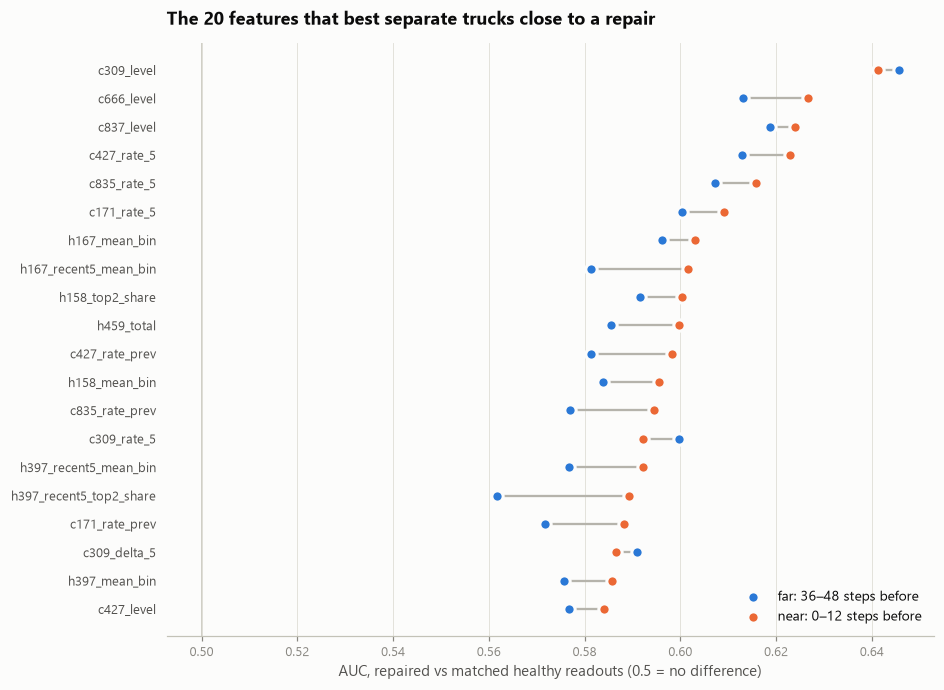

In [15]:
fig, ax = plt.subplots(figsize=(9, 7))
t = top.iloc[::-1]
y = np.arange(len(t))
ax.hlines(y, t.auc_far_36_48, t.auc_near_0_12, color=viz.GREY_LIGHT, lw=1.5, zorder=1)
ax.scatter(t.auc_far_36_48, y, s=55, color=viz.BLUE, edgecolor=viz.SURFACE, lw=2, zorder=2,
           label="far: 36–48 steps before")
ax.scatter(t.auc_near_0_12, y, s=55, color=viz.ORANGE, edgecolor=viz.SURFACE, lw=2, zorder=3,
           label="near: 0–12 steps before")
ax.axvline(0.5, color=viz.AXIS, lw=1, zorder=0)
ax.set_yticks(y, t.index)
ax.tick_params(axis="y", colors=viz.INK2, labelsize=8.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC, repaired vs matched healthy readouts (0.5 = no difference)")
ax.set_title("The 20 features that best separate trucks close to a repair")
ax.legend(loc="lower right")
viz.save(fig, "01_auc_before_repair", FIGS)
plt.show()

**Interpretation.** No single feature separates the groups well: the best reach an AUC of 0.62–0.65 (counter 309 level 0.64; counter 666 and 837 levels 0.62; counter 427 and 835 rates 0.62). More importantly, separation **barely grows towards the repair**: averaged per feature group, the distance from 0.5 rises by at most 0.006 between the far and near windows. The features that gain most are the recent-window ones: histogram 397 recent top-2 share (0.56 → 0.59), histogram 167 recent mean bin (0.58 → 0.60), and counter rates since the previous readout (+0.016 to +0.018). So the readouts say much more about **which** trucks are at risk than about **when** the repair is due, and the little timing signal there is sits in the recent-window features.

## 6. Missingness

SOURCES.md says fewer than 1% of values are missing per feature. Three checks:
1. NULL share per variable and split (for a histogram: the share of readouts where *any* bin is NULL).
2. Whether a histogram's bins go missing **together** (whole histogram absent from a readout)
   or one bin at a time; this decides whether imputation per bin makes sense.
3. Whether missingness is **informative**: does it differ by urgency class in training?
   If readouts close to a repair were more often incomplete, "is missing" would itself be a signal
   (and a possible leak to watch).

In [16]:
raw_cols = [c for c in q("DESCRIBE readouts")["column_name"] if c not in ("split", "vehicle_id", "time_step")]
var_cols = {}
for c in raw_cols:
    var_cols.setdefault(c.split("_")[0], []).append(c)

any_expr = ", ".join(
    f'avg(({" OR ".join(chr(34) + c + chr(34) + " IS NULL" for c in cs)})::INT) AS "any_{v}"'
    for v, cs in var_cols.items())
all_expr = ", ".join(
    f'avg(({" AND ".join(chr(34) + c + chr(34) + " IS NULL" for c in cs)})::INT) AS "all_{v}"'
    for v, cs in var_cols.items())
m = q(f"SELECT split, {any_expr}, {all_expr} FROM readouts GROUP BY split").set_index("split").loc[SPLITS]
missing = pd.DataFrame({
    split: {v: m.loc[split, f"any_{v}"] for v in var_cols} for split in SPLITS})
missing["kind"] = ["counter" if len(var_cols[v]) == 1 else f"histogram ({len(var_cols[v])} bins)" for v in missing.index]
missing["train_all_bins_null"] = [m.loc["train", f"all_{v}"] for v in missing.index]
missing["train_partial_share"] = 1 - missing["train_all_bins_null"] / missing["train"].replace(0, np.nan)
any_null = q(f'''SELECT split, avg(({" OR ".join(chr(34) + c + chr(34) + " IS NULL" for c in raw_cols)})::INT) AS share
                 FROM readouts GROUP BY split''').set_index("split").loc[SPLITS]
print("share of readouts with at least one NULL value:")
print(any_null["share"].map("{:.2%}".format).to_string())
missing.sort_values("train", ascending=False)

share of readouts with at least one NULL value:
split
train         2.00%
validation    2.01%
test          2.10%


,train,validation,test,kind,train_all_bins_null,train_partial_share
291,0.009,0.008,0.009,histogram (11 bins),0.009,0.000
459,0.007,0.007,0.007,histogram (20 bins),0.007,0.000
427,0.006,0.006,0.005,counter,0.006,0.000
100,0.006,0.006,0.005,counter,0.006,0.000
370,0.006,0.006,0.005,counter,0.006,0.000
167,0.003,0.003,0.004,histogram (10 bins),0.003,0.000
158,0.001,0.001,0.001,histogram (10 bins),0.001,0.000
397,0.001,0.001,0.001,histogram (36 bins),0.001,0.000
272,0.000,0.000,0.000,histogram (10 bins),0.000,0.000
666,0.000,0.000,0.000,counter,0.000,0.000


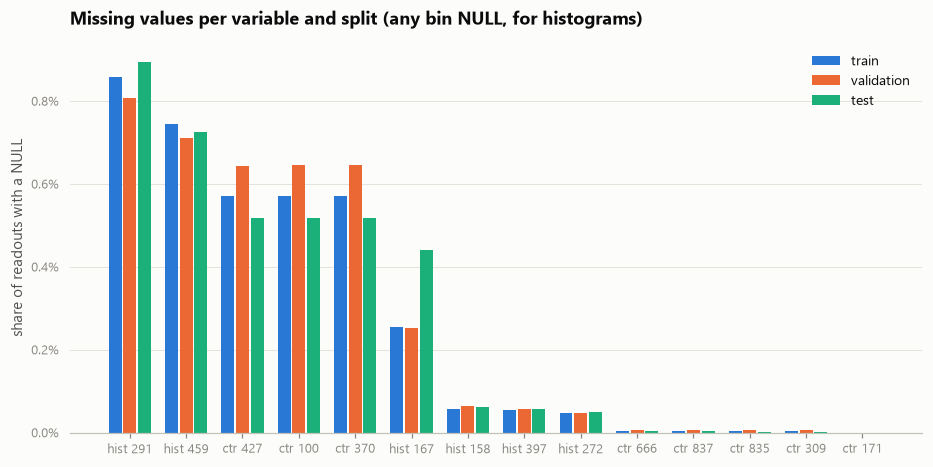

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.6))
order = missing.sort_values("train", ascending=False).index
x = np.arange(len(order))
w = 0.26
for i, split in enumerate(SPLITS):
    ax.bar(x + (i - 1) * w, missing.loc[order, split], width=w - 0.03,
           color=viz.SPLIT_COLORS[split], label=split)
ax.set_xticks(x, [f"{'hist' if len(var_cols[v]) > 1 else 'ctr'} {v}" for v in order], rotation=0, fontsize=8.5)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=1))
ax.set_ylabel("share of readouts with a NULL")
ax.set_title("Missing values per variable and split (any bin NULL, for histograms)")
ax.legend(loc="upper right")
viz.save(fig, "01_missingness", FIGS)
plt.show()

In [18]:
by_class = q(f'''
    SELECT coalesce(CAST(l.class_label AS VARCHAR), 'unknown') AS class_label,
           count(*) AS readouts,
           avg(({" OR ".join("r." + chr(34) + c + chr(34) + " IS NULL" for c in raw_cols)})::INT) AS share_with_null
    FROM readouts r JOIN train_readout_labels l USING (vehicle_id, time_step)
    WHERE r.split = 'train' GROUP BY 1 ORDER BY 1
''').set_index("class_label")
by_class

,readouts,share_with_null
class_label,,
0,894408,0.019
1,12511,0.014
2,6165,0.014
3,3204,0.014
4,3770,0.015
unknown,202394,0.025


**Interpretation.** Missingness is low and structured. About 2.0–2.1% of readouts have at least one NULL, and no variable exceeds 0.9% (worst: histogram 291 at 0.86% in training). Histogram bins are **always missing together** (whole histogram absent, never single bins), and counters 427, 100 and 370 go missing in the same readouts (99.9% overlap), so a readout loses whole blocks of data. The pattern is the same across splits, except histogram 167 (0.44% NULL in test vs 0.25% in training). Missingness is **not higher close to a repair**: 1.4–1.5% of readouts in classes 1–4 vs 1.9% in class 0 (2.5% in the unknown-class readouts at the end of censored histories). So "is missing" is not a repair signal or a leak. `HistGradientBoostingClassifier` handles NaN natively; the logistic model in notebook 03 needs imputation, ideally with one missing-indicator per missing block.

## 7. Three findings that shape notebooks 02 and 03

1. **Censoring dominates, so repair risk needs survival methods (→ notebook 02).** Only 9.6% of training trucks are seen being repaired; the other 90.4% leave the study without a repair, none of them before 121 time steps. Repairs happen across the whole life (from 73 to about 500 steps). A crude repair share understates the risk and mixes up exposure with risk. Notebook 02 uses Kaplan–Meier, Weibull and Cox models. The crude 13.6× spread between Spec_2 categories (and similar spreads in Spec_1 and Spec_7) makes survival by spec the first thing to test.

2. **The readouts identify *which* trucks are at risk far better than *when* (→ notebooks 02 and 03).** At the same age and Spec_0, trucks heading for a repair run most counters faster and sit higher in every histogram, and this gap is already there 48 steps before the repair (best single-feature AUC 0.62–0.65, almost unchanged between 36–48 and 0–12 steps before). That points to usage intensity as a hazard driver: notebook 02's Cox model should include early-life usage rates. For notebook 03 the expectation is that ranking trucks by risk will work, but telling the urgency classes 1–4 apart will be hard. The recent-window features carry what timing signal exists, and the expected-cost rule will lean on well-calibrated probabilities more than on a sharp argmax.

3. **Training prediction points must mimic validation, not uniform sampling (→ notebook 03).** Validation and test vehicles are cut earlier (median 34 vs 43 readouts), and their cut points are closer to a repair than random training readouts: class 4 is 1.5% of validation but 0.5% of random training readouts, while class 1 is over-represented 5×. Another 21% of random training readouts have an unknown class. Notebook 03 must choose a sampling or weighting scheme on validation, use vehicle-grouped CV, use rates rather than levels where the counters are cumulative, and handle the block-wise missingness (about 2% of readouts).

In [19]:
con.close()